In [3]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

In [4]:
'''Reuse the calibrated variables from notebook 3 if u wanna change save run notebook 3 befor you run this'''

frames = np.load("frames.npy")
times = np.load("times.npy")

region_history = np.load(
    "region_history.npy",
    allow_pickle=True
).tolist()

In [5]:
print("Frames:", len(frames))
print("Frame shape:", frames.shape)

Frames: 121
Frame shape: (121, 180, 360)


In [55]:
'''Just to verify everything is properly imported and there are no probs in note 3 and check the first static frame
as well just for the saftey's sake'''
print(f"Number of frames      : {len(frames)}")
print(f"Number of time points : {len(times)}")
print(f"Frame shape           : {frames[0].shape}")
print(f"Initial time          : {times[0]:.2f}")
print(f"Final time            : {times[-1]:.2f}")
print(f"Region history length : {len(region_history)}")


assert len(frames) == len(times), \
    "Number of frames and time points do not match."

assert len(frames) == len(region_history), \
    "Number of frames and region-history entries do not match."




Number of frames      : 121
Number of time points : 121
Frame shape           : (180, 360)
Initial time          : 0.00
Final time            : 30.00
Region history length : 121


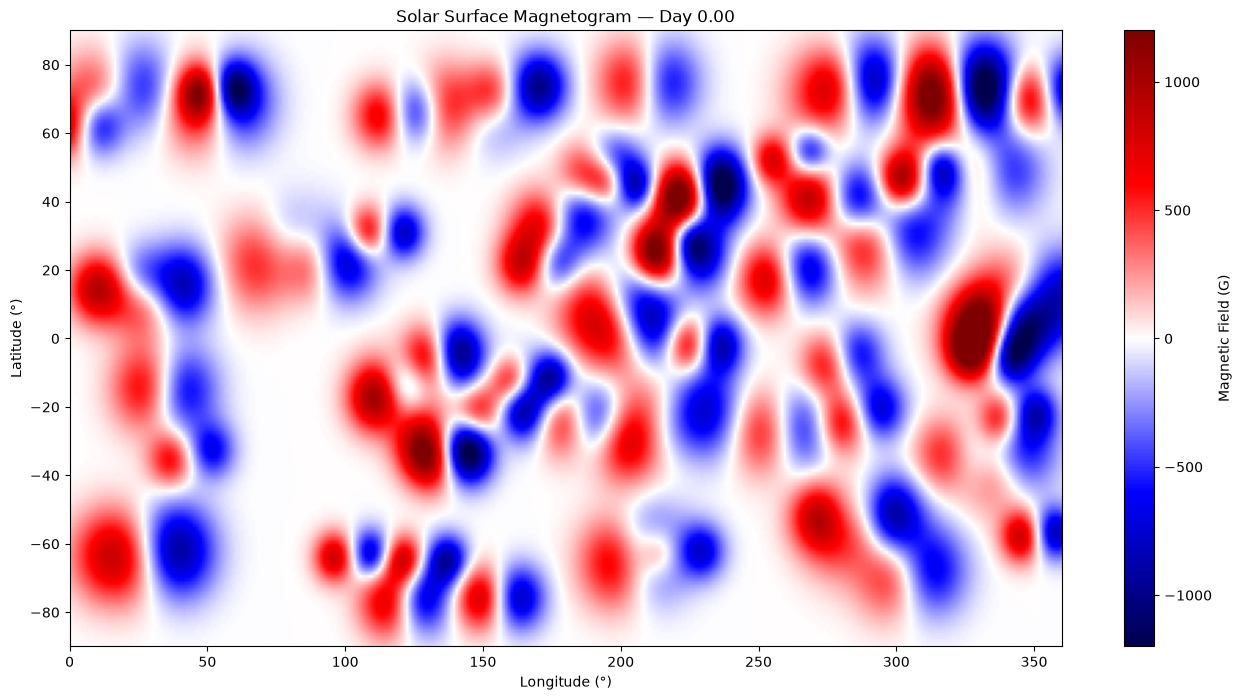

In [6]:
'''Animation block pre updating the frames'''



fig, ax = plt.subplots(figsize=(16, 8))

im = ax.imshow(
    frames[0],
    extent=[0, 360, -90, 90],
    origin="lower",
    aspect="auto",
    cmap="seismic",
    vmin=-1200,
    vmax=1200
)

ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")

ax.set_xlim(0, 360)
ax.set_ylim(-90, 90)

title = ax.set_title(
    f"Solar Surface Magnetogram — "
    f"Day {times[0]:.2f}"
)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Magnetic Field (G)")



In [7]:
'''frame update for the animation'''

# def update(frame_number):

#     # Update magnetic-field map
#     im.set_data(frames[frame_number])

#     # Update simulation time
#     title.set_text(
#         f"Solar Surface Magnetogram — "
#         f"Day {times[frame_number]:.2f}"
#     )

#     return im, title


'frame update for the animation'

In [8]:

# ani = FuncAnimation(
#     fig,
#     update,
#     frames=30,
#     interval=100,
#     blit=True
# )

# plt.close(fig)

'''The animation is gone run the sim for 100 ms ie 10 frames/sec'''

'The animation is gone run the sim for 100 ms ie 10 frames/sec'

In [9]:
from IPython.display import display

display(HTML(ani.to_jshtml()))

NameError: name 'ani' is not defined

In [ ]:
'''Save the file as gif and mp4'''

#GIF
# ani.save(
#     "solar_magnetic_evolution.gif",
#     writer="pillow",
#     fps=10
# )



'Save the file as gif and mp4'

In [ ]:
# MP4

# ani.save(
#     "solar_magnetic_evolution.mp4",
#     writer="ffmpeg",
#     fps=10,
#     dpi=150
# )

In [ ]:
# # n_frames = len(frames)

# # ani_full = FuncAnimation(
# #     fig,
# #     update,
# #     frames=n_frames,
# #     interval=100,
# #     blit=True
# )

In [ ]:
# # ani_full.save(
# #     "solar_magnetic_evolution.mp4",
# #     writer="ffmpeg",
# #     fps=10,
# #     dpi=150
# )

In [ ]:
print("Number of region frames", len(region_history))
print("regions at first frame\n", len(region_history[0]))


Number of region frames 121
regions at first frame
 73


In [ ]:
print(region_history[0][0])

{'lon': 31.793557980450533, 'lat': 27.051762835967715, 'solar_lat': -11.538340260481188, 'B0': 999.5578769347659, 'sigma': 9.648438390923406, 'seperation': 12.53678472871109, 'tilt': np.float64(2.705400835536663), 'age': 0}


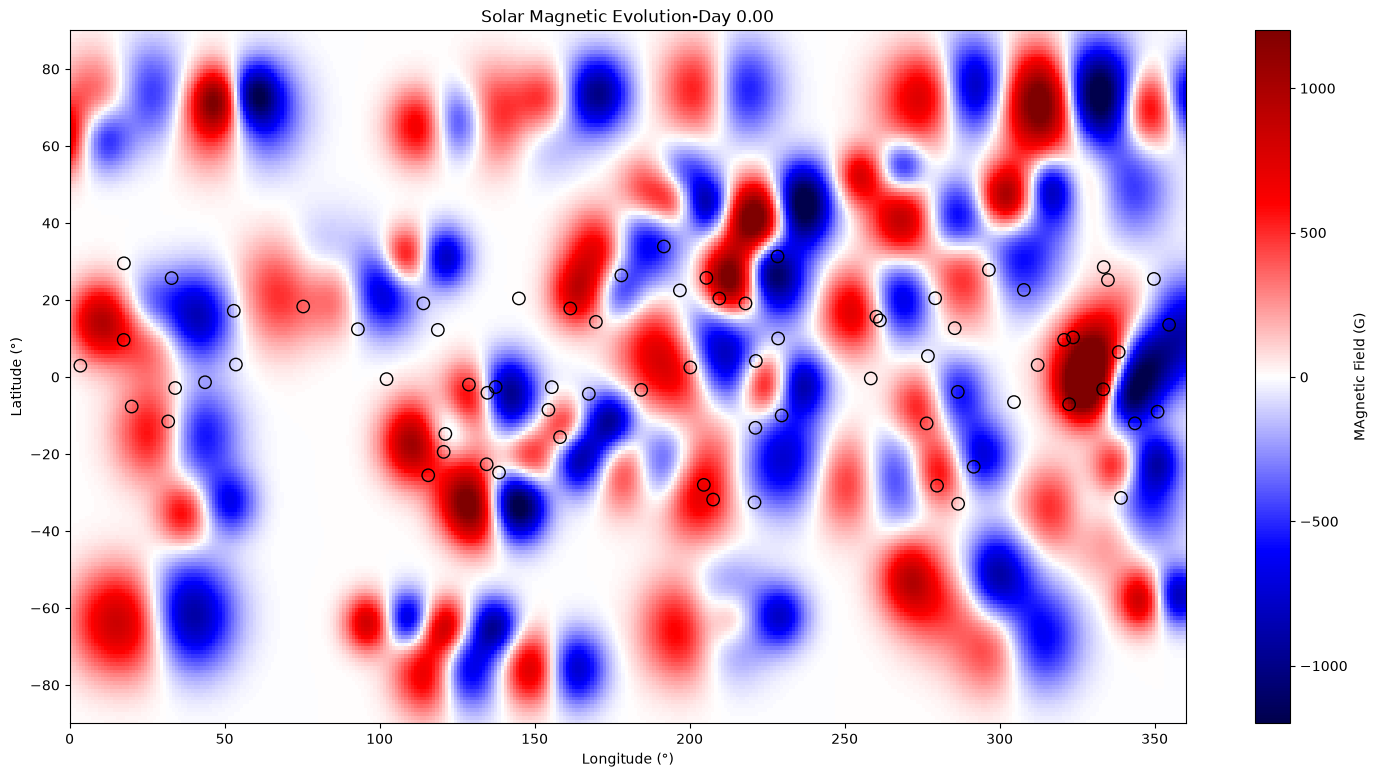

In [ ]:
''' adding a tracking figure for the active region history
    also pls be careful to use  defined axes and fig as fig2 or ax2 since we already used fig for the stage 1  we dont wannna
    or shuttle with the previous one
    add scatter markers as well for some clear latitude visual.
'''
fig2, ax2 = plt.subplots(figsize=(18,9))

im2 = ax2.imshow(
    frames[0],
    cmap = 'seismic',
    extent =[0,360,-90,90],
    origin='lower',
    aspect = 'auto',
    vmin = -1200,
    vmax = 1200
)

regions = region_history[0]

lons = [region["lon"] for region in regions]
lats = [region["solar_lat"] for region in regions]

scatter = ax2.scatter(

    lons, lats,
    s = 80,
    zorder = 10,
    facecolors = "None",
    edgecolors = "black",

)
ax2.set_xlabel("Longitude (°)")
ax2.set_ylabel("Latitude (°)")

ax2.set_xlim(0,360)
ax2.set_ylim(-90,90)
title2 = ax2.set_title("Solar Magnetic Evolution-" 
                      f"Day {times[0]:.2f}")

cbar2 = fig2.colorbar(im2, ax=ax2)
cbar2.set_label("MAgnetic Field (G)")

    

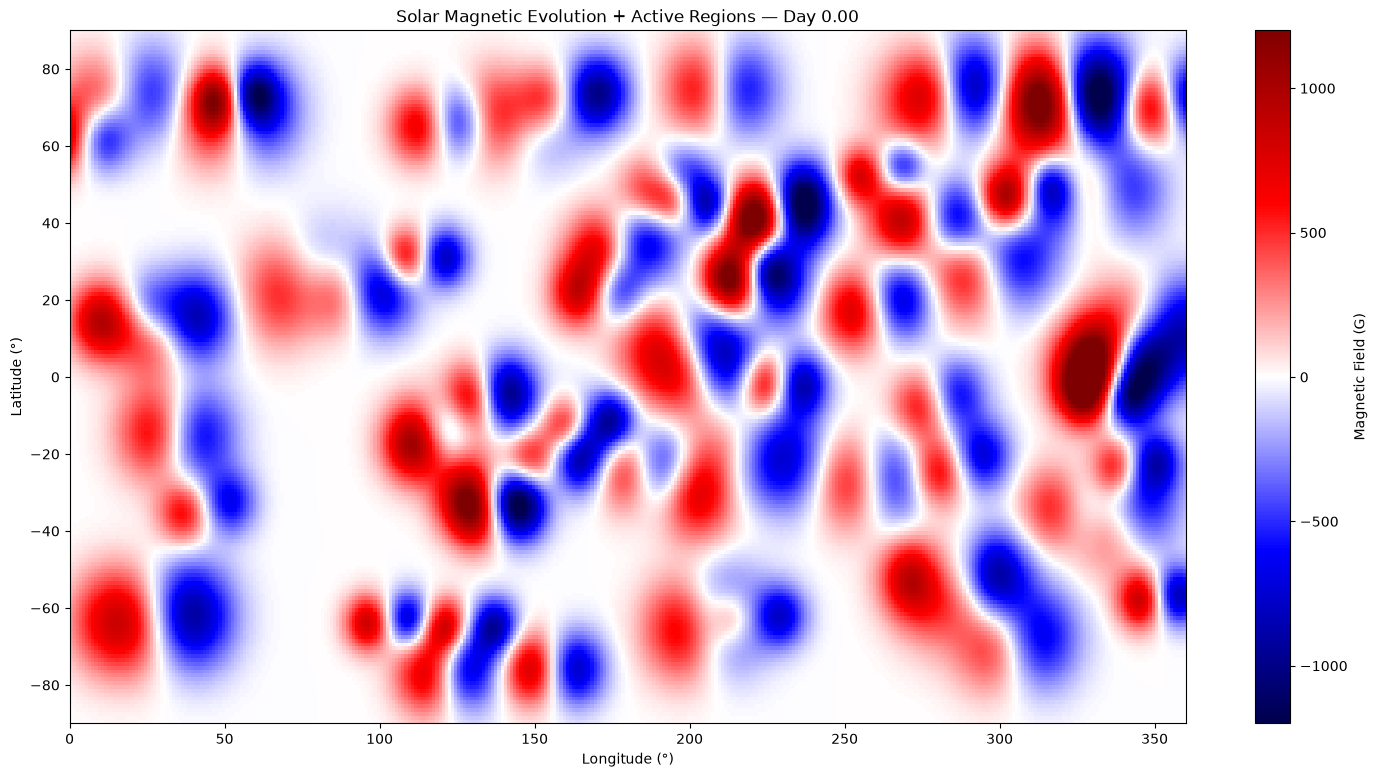

In [24]:
'''Tracking animation with a fresh figure'''

fig2,ax2 = plt.subplots(figsize=(18,9))

im2 = ax2.imshow(
    frames[0],
    extent = [0,360,-90,90],
    origin = 'lower',
    aspect = 'auto',
    cmap = 'seismic',
    vmin = -1200,
    vmax = 1200
)

ax2.set_xlabel("Longitude (°)")
ax2.set_ylabel("Latitude (°)")

ax2.set_xlim(0, 360)
ax2.set_ylim(-90, 90)

title2 = ax2.set_title(
    f"Solar Magnetic Evolution + Active Regions — "
    f"Day {times[0]:.2f}"
)

cbar2 = fig2.colorbar(im2, ax=ax2)
cbar2.set_label("Magnetic Field (G)")

plt.show()


In [25]:
scatter = ax2.scatter(
    [],
    [],
    s=60,
    facecolors="none",
    edgecolors="black",
    linewidths=1.2,
    zorder=10
)

In [29]:
'''update function for the animation'''

def update_reg(frame_number):

    im2.set_data(frames[frame_number])

    regions = region_history[frame_number]

    lons =[region['lon'] for region in regions]
    lats = [region["solar_lat"] for region in regions]

    if len(regions) > 0:
        scatter.set_offsets(
            np.column_stack((lons,lats))

        )
    else:
        scatter.set_offsets(
            np.empty((0,2))

        )

    title2.set_text(
        f"Solar Magnetic Evolution + Active Regions — "
        f"Day {times[frame_number]:.2f}"
    )

    return im2, scatter, title2


In [30]:
ani_regions = FuncAnimation(
    fig2,
    update_reg,
    frames=30,
    interval=100,
    blit=True
)

plt.close(fig2)

In [ ]:
# from IPython.display import display

# display(HTML(ani_regions.to_jshtml()))

In [32]:
''' '''

print("Frame 0:")
print("Number of regions:", len(region_history[0]))

print("\nFrame 60:")
print("Number of regions:", len(region_history[60]))

print("\nFrame 120:")
print("Number of regions:", len(region_history[120]))

Frame 0:
Number of regions: 73

Frame 60:
Number of regions: 73

Frame 120:
Number of regions: 73


In [ ]:
# ani_regions_full = FuncAnimation(
#     fig2,
#     update_reg,
#     frames=len(frames),
#     interval=100,
#     blit=True
# )

In [ ]:
# ani_regions_full.save(
#     "solar_mag_reg_evolution.mp4",
#     writer="ffmpeg",
#     fps=10,
#     dpi=150
# )

In [ ]:
# from IPython.display import Video, display

# display(Video("solar_mag_reg_evolution.mp4", embed=True))

Initial active regions: 73
Final active regions:   73
Maximum active regions: 73


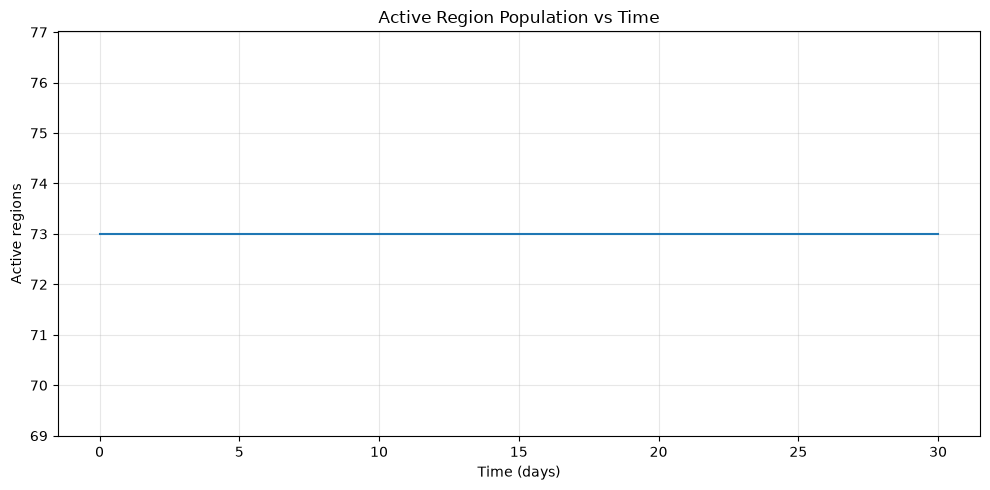

In [47]:
region_counts = [len(regions) for regions in region_history]

print(f"Initial active regions: {region_counts[0]}")
print(f"Final active regions:   {region_counts[-1]}")
print(f"Maximum active regions: {max(region_counts)}")

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(times, region_counts)

plt.xlabel("Time (days)")
plt.ylabel("Active regions")
plt.title("Active Region Population vs Time")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
'''LOoks like smtg is wrong with the decay cuz none of my regions are decaying this maybe due to the fact 
that the time required for a region decay is more than our simulation timeframe 
our time frame is 30 days while the decay takes 68.75 days to reach the threshold
one feature that heps us observe the decay is the magn strengths which do go down but our time 
frame is to short to simulate the decay of our regions
 '''

initial_B0 = [r["B0"] for r in region_history[0]]
final_B0 = [r["B0"] for r in region_history[-1]]

print(f"Initial mean B0: {np.mean(initial_B0):.2f}")
print(f"Final mean B0:   {np.mean(final_B0):.2f}")

print(f"Initial max B0:  {np.max(initial_B0):.2f}")
print(f"Final max B0:    {np.max(final_B0):.2f}")

print(f"Initial min B0:  {np.min(initial_B0):.2f}")
print(f"Final min B0:    {np.min(final_B0):.2f}")
'''
Initial mean B0: 784.99
Final mean B0:   544.99
Initial max B0:  999.56
Final max B0:    759.56
Initial min B0:  603.74
Final min B0:    363.74

evidently so.... Ig it is fine, honest to be fair
'''

Initial mean B0: 784.99
Final mean B0:   544.99
Initial max B0:  999.56
Final max B0:    759.56
Initial min B0:  603.74
Final min B0:    363.74


'\nInitial mean B0: 784.99\nFinal mean B0:   544.99\nInitial max B0:  999.56\nFinal max B0:    759.56\nInitial min B0:  603.74\nFinal min B0:    363.74\n'

In [57]:
# A final diagnostic ode 

print(f"Simulation duration : {times[-1]:.2f} days")
print(f"Time step           : 0.25 days")
print(f"Number of frames    : {len(frames)}")
print(f"Initial regions     : {len(region_history[0])}")
print(f"Final regions       : {len(region_history[-1])}")
print(f"Decay rate          : 8.00 field-units/day")
print(f"Defunct threshold   : 50.00")
print(f"MP4 size            : 3.28 MB")
print(f"Animation duration  : ~12 s")


Simulation duration : 30.00 days
Time step           : 0.25 days
Number of frames    : 121
Initial regions     : 73
Final regions       : 73
Decay rate          : 8.00 field-units/day
Defunct threshold   : 50.00
MP4 size            : 3.28 MB
Animation duration  : ~12 s


In [1]:
import pickle



In [6]:
sim_data = {
    "frames": frames,
    "times": times,
    "region_history": region_history
}

with open("defunct_stage2_data.pkl", "wb") as f:
    pickle.dump(sim_data, f)